# EDA — DATAMARCA: transacciones (POS) y logs de e-commerce

Análisis exploratorio en dos partes: **Parte 1** transacciones de punto de venta (CSV, 5.000 registros, 7 columnas incluida `user_id`) y **Parte 2** logs de eventos de e-commerce (JSON, 5.000 eventos), que resultan ser la **traza digital de esas mismas 5.000 compras**, más el cruce entre ambas fuentes.

**Contenido**
1. Carga y vista general
2. Calidad de datos (incluye revisión de codificación de texto)
3. Ingeniería de variables
4. Análisis univariado (monto, categóricas y usuarios)
5. Análisis bivariado (incluye comportamiento por usuario)
6. Patrones temporales
7. Cruces entre variables y pruebas estadísticas
8. Conclusiones de la Parte 1

**Parte 2 — Logs de e-commerce** (secciones 9 a 14)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titleweight"] = "bold"
pd.options.display.float_format = "{:,.2f}".format

fmt_cop = mtick.FuncFormatter(lambda x, _: f"${x:,.0f}")

## 1. Carga y vista general

In [2]:
df = pd.read_csv("DATAMARCA_transacciones_5000_real.csv", parse_dates=["timestamp"])
print(f"Filas: {df.shape[0]:,} | Columnas: {df.shape[1]}")
df.head(10)

Filas: 5,000 | Columnas: 7


,transaction_id,user_id,timestamp,store_id,product_category,amount_cop,payment_method
0,TXN10000,usr_2939,2026-09-15 08:02:06,MED-01,Snacks,74979,App
1,TXN10001,usr_9520,2026-09-15 08:02:39,BOG-02,Frutas,62048,App
2,TXN10002,usr_6406,2026-09-15 08:06:44,BAR-01,Bebidas,17878,App
3,TXN10003,usr_9223,2026-09-15 08:15:17,BOG-01,PanaderÃ­a,4715,Tarjeta
4,TXN10004,usr_3245,2026-09-15 08:39:12,MED-02,LÃ¡cteos,8920,Efectivo
5,TXN10005,usr_3807,2026-09-15 08:46:15,MED-01,PanaderÃ­a,83988,Efectivo
6,TXN10006,usr_2836,2026-09-15 08:50:51,BOG-02,LÃ¡cteos,61122,Tarjeta
7,TXN10007,usr_8562,2026-09-15 08:54:27,MED-02,Licores,51123,Tarjeta
8,TXN10008,usr_2479,2026-09-15 09:08:58,MED-02,Licores,8300,Efectivo
9,TXN10009,usr_2763,2026-09-15 09:28:07,CAL-01,Carnes,47965,Tarjeta


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   transaction_id    5000 non-null   str           
 1   user_id           5000 non-null   str           
 2   timestamp         5000 non-null   datetime64[us]
 3   store_id          5000 non-null   str           
 4   product_category  5000 non-null   str           
 5   amount_cop        5000 non-null   int64         
 6   payment_method    5000 non-null   str           
dtypes: datetime64[us](1), int64(1), str(5)
memory usage: 273.6 KB


In [4]:
df.describe(include="all").T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
transaction_id,5000,5000,TXN10000,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
user_id,5000,672,usr_6260,128,NaN,NaN,NaN,NaN,NaN,NaN,NaN
timestamp,5000,NaN,NaN,NaN,2026-09-30 17:32:06.455200,2026-09-15 08:02:06,2026-09-23 05:46:35,2026-09-30 20:36:10,2026-10-08 07:27:10.750000,2026-10-15 17:59:48,NaN
store_id,5000,6,BOG-02,905,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_category,5000,10,Snacks,514,NaN,NaN,NaN,NaN,NaN,NaN,NaN
amount_cop,"5,000.00",NaN,NaN,NaN,"47,089.01","2,005.00","15,335.00","33,650.00","63,212.50","413,280.00","44,477.78"
payment_method,5000,4,Tarjeta,2296,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Calidad de datos
Revisamos nulos, duplicados, llaves, rangos y consistencia de categorías.

In [5]:
calidad = pd.DataFrame({
    "nulos": df.isna().sum(),
    "% nulos": df.isna().mean() * 100,
    "únicos": df.nunique(),
})
display(calidad)

print("Filas duplicadas (completas):", df.duplicated().sum())
print("transaction_id duplicados:   ", df["transaction_id"].duplicated().sum())
print("timestamps duplicados:       ", df["timestamp"].duplicated().sum())
print("Orden cronológico creciente: ", df["timestamp"].is_monotonic_increasing)
print("Montos <= 0:                 ", (df["amount_cop"] <= 0).sum())
print("Rango de fechas:", df["timestamp"].min(), "→", df["timestamp"].max())

,nulos,% nulos,únicos
transaction_id,0,0.00,5000
user_id,0,0.00,672
timestamp,0,0.00,4995
store_id,0,0.00,6
product_category,0,0.00,10
amount_cop,0,0.00,4868
payment_method,0,0.00,4


Filas duplicadas (completas): 0
transaction_id duplicados:    0
timestamps duplicados:        5
Orden cronológico creciente:  True
Montos <= 0:                  0
Rango de fechas: 2026-09-15 08:02:06 → 2026-10-15 17:59:48


In [6]:
# Consistencia de categorías (espacios, mayúsculas/minúsculas)
for c in ["store_id", "product_category", "payment_method"]:
    vals = df[c].unique()
    limpio = pd.Series(vals).str.strip().str.lower().nunique()
    print(f"{c:18s} valores={len(vals):2d} | tras normalizar={limpio:2d} | {sorted(vals)}")

# Formato del ID
print("\nID con formato TXN#####:", df["transaction_id"].str.fullmatch(r"TXN\d{5}").all())

store_id           valores= 6 | tras normalizar= 6 | ['BAR-01', 'BOG-01', 'BOG-02', 'CAL-01', 'MED-01', 'MED-02']
product_category   valores=10 | tras normalizar=10 | ['Aseo', 'Bebidas', 'Carnes', 'Frutas', 'Granos', 'Licores', 'LÃ¡cteos', 'PanaderÃ\xada', 'Snacks', 'Verduras']
payment_method     valores= 4 | tras normalizar= 4 | ['App', 'Bono', 'Efectivo', 'Tarjeta']

ID con formato TXN#####: True


In [7]:
# Codificación del texto: ¿hay "mojibake" (UTF-8 mal leído como cp1252, p. ej. "LÃ¡cteos")?
def reparar_texto(s):
    try:
        return s.encode("cp1252").decode("utf-8") if "Ã" in s else s
    except (UnicodeEncodeError, UnicodeDecodeError):
        return s

cols_txt = ["transaction_id", "user_id", "store_id", "product_category", "payment_method"]
corruptas = {c: int(df[c].str.contains("Ã", regex=False).sum()) for c in cols_txt}
print("Filas con texto corrupto por columna:", corruptas)
print("Categorías afectadas:", sorted(df.loc[df["product_category"].str.contains("Ã", regex=False), "product_category"].unique()))

df["product_category"] = df["product_category"].map(reparar_texto)
print("\nTras reparar →", sorted(df["product_category"].unique()))

# Formato del ID de usuario (nuevo en este CSV)
print("ID usuario con formato usr_####:     ", df["user_id"].str.fullmatch(r"usr_\d{4}").all())

Filas con texto corrupto por columna: {'transaction_id': 0, 'user_id': 0, 'store_id': 0, 'product_category': 983, 'payment_method': 0}
Categorías afectadas: ['LÃ¡cteos', 'PanaderÃ\xada']

Tras reparar → ['Aseo', 'Bebidas', 'Carnes', 'Frutas', 'Granos', 'Licores', 'Lácteos', 'Panadería', 'Snacks', 'Verduras']
ID usuario con formato usr_####:      True


> **Hallazgo de calidad:** en este CSV las categorías `Lácteos` y `Panadería` están guardadas con la codificación dañada (`LÃ¡cteos`, `PanaderÃ­a`). Se repara aquí para poder analizarlas y, sobre todo, para poder cruzarlas con el JSON; lo correcto es corregirlo en el origen. Como el daño dejaba **10 categorías "distintas" igualmente**, `nunique()` no lo delataba.

In [8]:
# Timestamps repetidos: ¿son transacciones distintas en el mismo segundo?
rep = df[df["timestamp"].duplicated(keep=False)].sort_values("timestamp")
pares = rep.groupby("timestamp").agg(tiendas=("store_id", "nunique"), categorias=("product_category", "nunique"),
                                     usuarios=("user_id", "nunique"))
print(f"Pares con timestamp repetido: {len(pares)} | en tiendas distintas: {(pares.tiendas > 1).sum()} | "
      f"en categorías distintas: {(pares.categorias > 1).sum()} | de usuarios distintos: {(pares.usuarios > 1).sum()}")
print(f"Pares que difieren en tienda Y categoría: {((pares.tiendas > 1) & (pares.categorias > 1)).sum()}")
rep.head(10)

Pares con timestamp repetido: 5 | en tiendas distintas: 3 | en categorías distintas: 4 | de usuarios distintos: 5
Pares que difieren en tienda Y categoría: 3


,transaction_id,user_id,timestamp,store_id,product_category,amount_cop,payment_method
575,TXN10575,usr_6986,2026-09-18 22:39:15,MED-02,Carnes,87269,Tarjeta
576,TXN10576,usr_7341,2026-09-18 22:39:15,BAR-01,Aseo,145138,Tarjeta
609,TXN10609,usr_1408,2026-09-19 03:20:21,CAL-01,Bebidas,14520,Tarjeta
610,TXN10610,usr_1301,2026-09-19 03:20:21,CAL-01,Bebidas,61656,Efectivo
2317,TXN12317,usr_6260,2026-09-29 15:48:35,MED-02,Carnes,44293,App
2318,TXN12318,usr_6194,2026-09-29 15:48:35,BOG-01,Licores,4229,Tarjeta
4014,TXN14014,usr_8960,2026-10-09 21:44:51,BOG-01,Licores,99277,Efectivo
4015,TXN14015,usr_7525,2026-10-09 21:44:51,CAL-01,Lácteos,180440,Tarjeta
4260,TXN14260,usr_3737,2026-10-11 11:17:13,BOG-01,Aseo,61660,Efectivo
4261,TXN14261,usr_9296,2026-10-11 11:17:13,BOG-01,Granos,5386,Tarjeta


## 3. Ingeniería de variables
Derivamos variables de tiempo y la **ciudad** a partir del prefijo de `store_id`
(`BOG`=Bogotá, `MED`=Medellín, `CAL`=Cali, `BAR`=Barranquilla — *supuesto basado en los códigos*).

In [9]:
ciudades = {"BOG": "Bogotá", "MED": "Medellín", "CAL": "Cali", "BAR": "Barranquilla"}
dias_es = {0: "Lun", 1: "Mar", 2: "Mié", 3: "Jue", 4: "Vie", 5: "Sáb", 6: "Dom"}
orden_dias = list(dias_es.values())

df["fecha"] = df["timestamp"].dt.normalize()
df["hora"] = df["timestamp"].dt.hour
df["dia_semana"] = pd.Categorical(df["timestamp"].dt.dayofweek.map(dias_es), categories=orden_dias, ordered=True)
df["semana"] = df["timestamp"].dt.to_period("W-SUN").dt.start_time
df["es_fin_semana"] = df["timestamp"].dt.dayofweek >= 5
df["ciudad"] = df["store_id"].str[:3].map(ciudades)
df["franja"] = pd.cut(df["hora"], bins=[-1, 5, 11, 17, 23],
                      labels=["Madrugada (0-5)", "Mañana (6-11)", "Tarde (12-17)", "Noche (18-23)"])
df["log_monto"] = np.log10(df["amount_cop"])

df[["timestamp", "store_id", "ciudad", "hora", "dia_semana", "franja", "amount_cop"]].head()

,timestamp,store_id,ciudad,hora,dia_semana,franja,amount_cop
0,2026-09-15 08:02:06,MED-01,Medellín,8,Mar,Mañana (6-11),74979
1,2026-09-15 08:02:39,BOG-02,Bogotá,8,Mar,Mañana (6-11),62048
2,2026-09-15 08:06:44,BAR-01,Barranquilla,8,Mar,Mañana (6-11),17878
3,2026-09-15 08:15:17,BOG-01,Bogotá,8,Mar,Mañana (6-11),4715
4,2026-09-15 08:39:12,MED-02,Medellín,8,Mar,Mañana (6-11),8920


## 4. Análisis univariado

### 4.1 Monto de la transacción (`amount_cop`)

In [10]:
resumen = df["amount_cop"].describe(percentiles=[.01, .05, .25, .5, .75, .9, .95, .99])
resumen["asimetría"] = df["amount_cop"].skew()
resumen["curtosis"] = df["amount_cop"].kurt()
resumen["coef. variación"] = df["amount_cop"].std() / df["amount_cop"].mean()
resumen.to_frame("amount_cop")

,amount_cop
count,"5,000.00"
mean,"47,089.01"
std,"44,477.78"
min,"2,005.00"
1%,"2,666.82"
5%,"4,433.50"
25%,"15,335.00"
50%,"33,650.00"
75%,"63,212.50"
90%,"105,519.70"


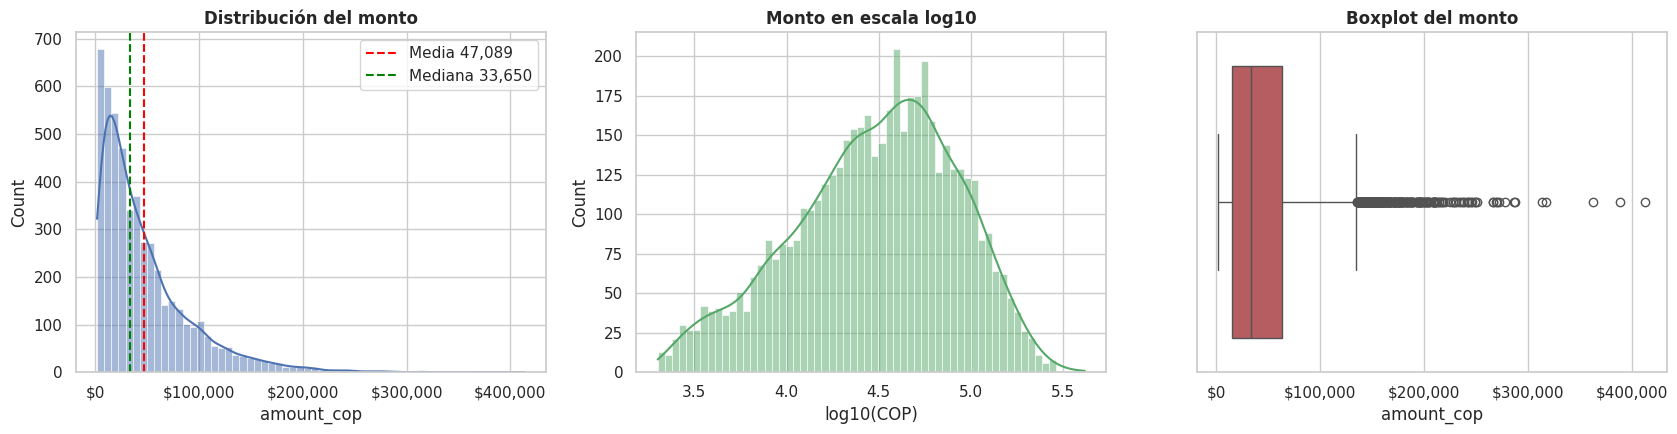

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))

sns.histplot(df["amount_cop"], bins=60, kde=True, ax=ax[0], color="#4C72B0")
ax[0].axvline(df["amount_cop"].mean(), color="red", ls="--", label=f"Media {df['amount_cop'].mean():,.0f}")
ax[0].axvline(df["amount_cop"].median(), color="green", ls="--", label=f"Mediana {df['amount_cop'].median():,.0f}")
ax[0].set_title("Distribución del monto"); ax[0].xaxis.set_major_formatter(fmt_cop); ax[0].legend()

sns.histplot(df["log_monto"], bins=60, kde=True, ax=ax[1], color="#55A868")
ax[1].set_title("Monto en escala log10"); ax[1].set_xlabel("log10(COP)")

sns.boxplot(x=df["amount_cop"], ax=ax[2], color="#C44E52")
ax[2].set_title("Boxplot del monto"); ax[2].xaxis.set_major_formatter(fmt_cop)
plt.tight_layout(); plt.show()

In [12]:
# Outliers por regla IQR (1.5 × IQR)
q1, q3 = df["amount_cop"].quantile([.25, .75])
iqr = q3 - q1
lim_sup = q3 + 1.5 * iqr
outliers = df[df["amount_cop"] > lim_sup]
print(f"Límite superior IQR: ${lim_sup:,.0f}")
print(f"Outliers: {len(outliers)} ({len(outliers)/len(df):.2%}) | aportan {outliers['amount_cop'].sum()/df['amount_cop'].sum():.2%} de las ventas")
outliers.sort_values("amount_cop", ascending=False).head(10)[["transaction_id","timestamp","store_id","product_category","amount_cop","payment_method"]]

Límite superior IQR: $135,029
Outliers: 262 (5.24%) | aportan 19.73% de las ventas


,transaction_id,timestamp,store_id,product_category,amount_cop,payment_method
3150,TXN13150,2026-10-04 15:25:21,CAL-01,Granos,413280,Efectivo
2304,TXN12304,2026-09-29 13:52:26,BAR-01,Verduras,389202,Tarjeta
2162,TXN12162,2026-09-28 18:17:28,MED-02,Frutas,362690,Efectivo
523,TXN10523,2026-09-18 14:22:20,MED-01,Snacks,317130,App
1515,TXN11515,2026-09-24 18:57:32,BOG-02,Carnes,313276,App
3861,TXN13861,2026-10-08 21:41:43,BAR-01,Licores,287510,App
3924,TXN13924,2026-10-09 08:51:36,MED-02,Aseo,286344,Tarjeta
2361,TXN12361,2026-09-29 21:21:09,MED-01,Licores,278119,App
191,TXN10191,2026-09-16 14:37:48,BOG-02,Granos,272492,Efectivo
2212,TXN12212,2026-09-29 02:43:51,BAR-01,Carnes,270110,Efectivo


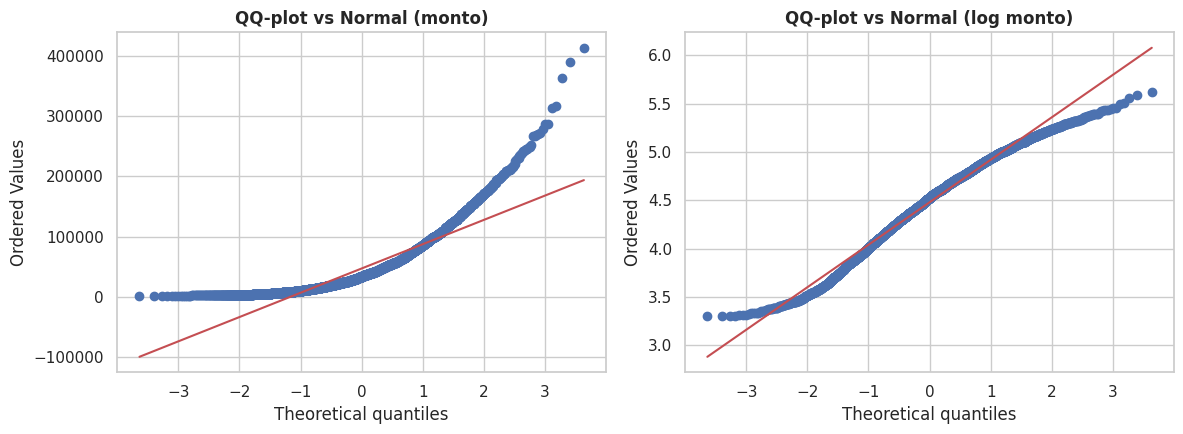

Shapiro (muestra 5000) monto:     p = 1.6953085254662946e-59
Shapiro (muestra 5000) log monto: p = 2.2738862847545358e-23


In [13]:
# ¿El monto sigue una distribución log-normal? (comparación visual con QQ-plot)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
stats.probplot(df["amount_cop"], dist="norm", plot=ax[0]); ax[0].set_title("QQ-plot vs Normal (monto)")
stats.probplot(df["log_monto"], dist="norm", plot=ax[1]); ax[1].set_title("QQ-plot vs Normal (log monto)")
plt.tight_layout(); plt.show()

print("Shapiro (muestra 5000) monto:     p =", stats.shapiro(df["amount_cop"])[1])
print("Shapiro (muestra 5000) log monto: p =", stats.shapiro(df["log_monto"])[1])

### 4.2 Variables categóricas

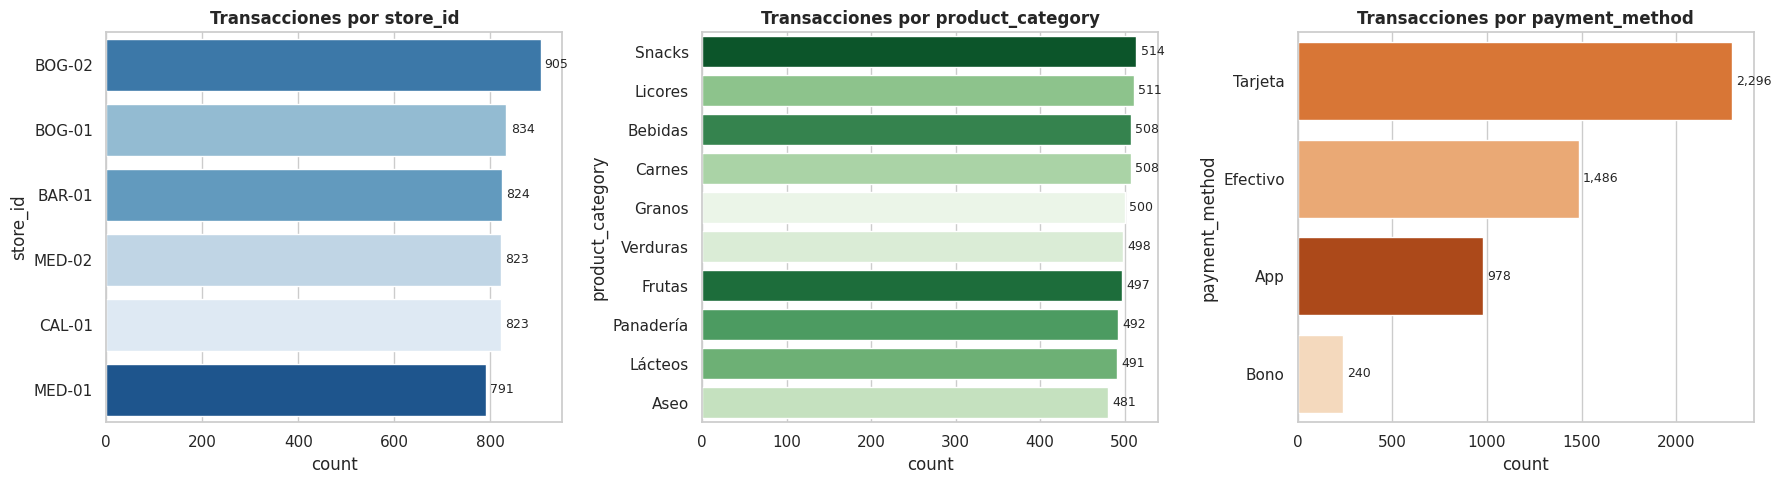

In [14]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for a, c, pal in zip(ax, ["store_id", "product_category", "payment_method"], ["Blues_r", "Greens_r", "Oranges_r"]):
    orden = df[c].value_counts().index
    sns.countplot(data=df, y=c, order=orden, ax=a, palette=pal, hue=c, legend=False)
    a.set_title(f"Transacciones por {c}")
    for p in a.patches:
        a.annotate(f"{int(p.get_width()):,}", (p.get_width(), p.get_y() + p.get_height()/2),
                   va="center", ha="left", fontsize=9, xytext=(3, 0), textcoords="offset points")
plt.tight_layout(); plt.show()

In [15]:
for c in ["store_id", "ciudad", "product_category", "payment_method"]:
    t = df[c].value_counts().to_frame("n")
    t["%"] = t["n"] / t["n"].sum() * 100
    display(t)

,n,%
store_id,,
BOG-02,905,18.10
BOG-01,834,16.68
BAR-01,824,16.48
MED-02,823,16.46
CAL-01,823,16.46
MED-01,791,15.82


,n,%
ciudad,,
Bogotá,1739,34.78
Medellín,1614,32.28
Barranquilla,824,16.48
Cali,823,16.46


,n,%
product_category,,
Snacks,514,10.28
Licores,511,10.22
Bebidas,508,10.16
Carnes,508,10.16
Granos,500,10.00
Verduras,498,9.96
Frutas,497,9.94
Panadería,492,9.84
Lácteos,491,9.82


,n,%
payment_method,,
Tarjeta,2296,45.92
Efectivo,1486,29.72
App,978,19.56
Bono,240,4.80


In [16]:
# ¿Las categorías están balanceadas? Chi-cuadrado contra distribución uniforme
for c in ["store_id", "product_category", "payment_method"]:
    chi, p = stats.chisquare(df[c].value_counts())
    print(f"{c:18s} χ²={chi:8.2f}  p={p:.4f}  →", "NO uniforme" if p < 0.05 else "compatible con uniforme")

store_id           χ²=    8.68  p=0.1227  → compatible con uniforme
product_category   χ²=    1.93  p=0.9926  → compatible con uniforme
payment_method     χ²= 1795.12  p=0.0000  → NO uniforme


### 4.3 Usuarios (`user_id`)

Usuarios únicos: 672 | con 2+ compras: 600 (89.3%)
Compras por usuario: mediana 5 | media 7.4 | máx 128 (usr_6260)
Top 10 usuarios: 14.8% de las transacciones y 14.4% de las ventas
Top 5% de usuarios (33): 28.6% de las transacciones y 28.1% de las ventas
Usuarios que compran en más de una ciudad: 0 de 672


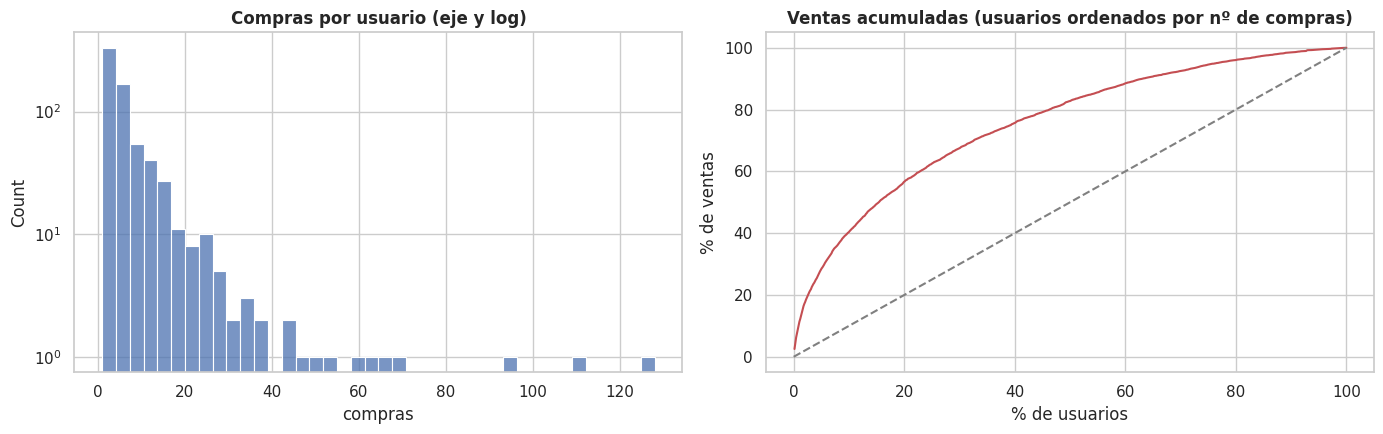

,usuarios,transacciones,compras por usuario
ciudad,,,
Barranquilla,172,824,4.79
Bogotá,180,1739,9.66
Cali,157,823,5.24
Medellín,163,1614,9.90


,compras,ventas,ciudades,tiendas
user_id,,,,
usr_6260,128,5956517,1,2
usr_3632,109,4488170,1,1
usr_7358,94,4309852,1,2
usr_9520,68,3118512,1,2
usr_9296,66,2973697,1,2
usr_8091,63,3077538,1,2
usr_9950,61,2889920,1,2
usr_1787,54,2057828,1,2


In [17]:
por_usuario = df.groupby("user_id").agg(compras=("amount_cop", "size"), ventas=("amount_cop", "sum"),
                                        ciudades=("ciudad", "nunique"), tiendas=("store_id", "nunique"))
print(f"Usuarios únicos: {len(por_usuario):,} | con 2+ compras: {(por_usuario.compras > 1).sum():,} ({(por_usuario.compras > 1).mean():.1%})")
print(f"Compras por usuario: mediana {por_usuario.compras.median():.0f} | media {por_usuario.compras.mean():.1f} | máx {por_usuario.compras.max()} ({por_usuario.compras.idxmax()})")

top = por_usuario.sort_values("compras", ascending=False)
n5 = int(len(top) * .05)
print(f"Top 10 usuarios: {top.head(10).compras.sum() / len(df):.1%} de las transacciones y {top.head(10).ventas.sum() / df.amount_cop.sum():.1%} de las ventas")
print(f"Top 5% de usuarios ({n5}): {top.head(n5).compras.sum() / len(df):.1%} de las transacciones y {top.head(n5).ventas.sum() / df.amount_cop.sum():.1%} de las ventas")
print(f"Usuarios que compran en más de una ciudad: {(por_usuario.ciudades > 1).sum()} de {len(por_usuario)}")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(por_usuario["compras"], bins=40, ax=ax[0], color="#4C72B0"); ax[0].set_yscale("log")
ax[0].set_title("Compras por usuario (eje y log)"); ax[0].set_xlabel("compras")
acum = top["ventas"].cumsum() / top["ventas"].sum() * 100
ax[1].plot(np.arange(1, len(top) + 1) / len(top) * 100, acum.values, color="#C44E52")
ax[1].plot([0, 100], [0, 100], ls="--", color="grey"); ax[1].set_title("Ventas acumuladas (usuarios ordenados por nº de compras)")
ax[1].set_xlabel("% de usuarios"); ax[1].set_ylabel("% de ventas")
plt.tight_layout(); plt.show()

uc = df.groupby("ciudad").agg(usuarios=("user_id", "nunique"), transacciones=("amount_cop", "size"))
uc["compras por usuario"] = uc["transacciones"] / uc["usuarios"]
display(uc)
top.head(8)

## 5. Análisis bivariado

### 5.1 Monto por categoría de producto

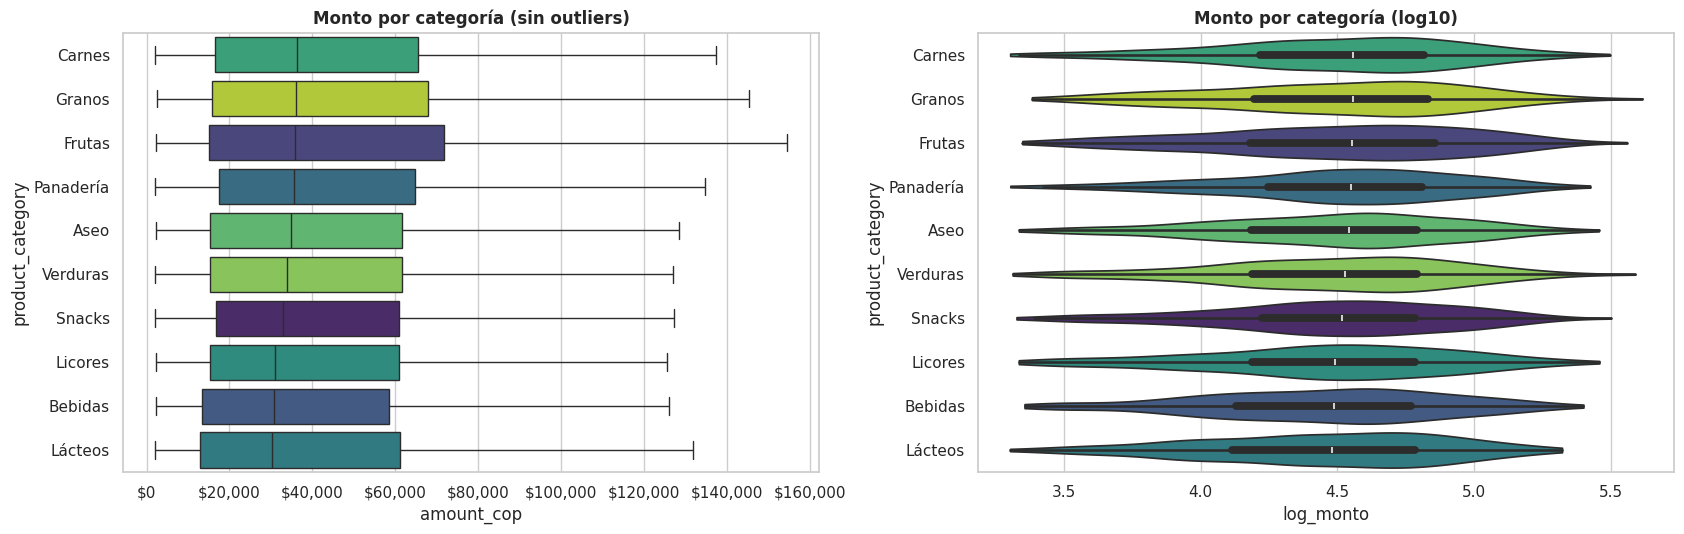

,transacciones,ventas,ticket_medio,mediana,p90
product_category,,,,,
Frutas,497,25187823,"50,679.72","35,727.00","120,157.00"
Granos,500,24851183,"49,702.37","35,986.00","111,084.70"
Carnes,508,24847388,"48,912.18","36,181.00","107,808.60"
Panadería,492,23764186,"48,301.19","35,590.00","109,396.40"
Licores,511,23754897,"46,487.08","30,924.00","102,988.00"
Snacks,514,23560518,"45,837.58","32,802.00","101,876.40"
Verduras,498,23267866,"46,722.62","33,856.50","102,325.40"
Aseo,481,22557725,"46,897.56","34,774.00","103,594.00"
Bebidas,508,22446974,"44,186.96","30,828.00","102,444.30"


In [18]:
orden = df.groupby("product_category")["amount_cop"].median().sort_values(ascending=False).index
fig, ax = plt.subplots(1, 2, figsize=(17, 5.5))
sns.boxplot(data=df, y="product_category", x="amount_cop", order=orden, ax=ax[0], showfliers=False, palette="viridis", hue="product_category", legend=False)
ax[0].set_title("Monto por categoría (sin outliers)"); ax[0].xaxis.set_major_formatter(fmt_cop)
sns.violinplot(data=df, y="product_category", x="log_monto", order=orden, ax=ax[1], palette="viridis", hue="product_category", legend=False, cut=0)
ax[1].set_title("Monto por categoría (log10)")
plt.tight_layout(); plt.show()

(df.groupby("product_category")["amount_cop"]
   .agg(transacciones="count", ventas="sum", ticket_medio="mean", mediana="median", p90=lambda s: s.quantile(.9))
   .sort_values("ventas", ascending=False))

### 5.2 Ventas por tienda y ciudad

,,transacciones,ventas,ticket_medio,mediana,% ventas
ciudad,store_id,,,,,
Bogotá,BOG-02,905,44284830,"48,933.51","34,396.00",18.81
Medellín,MED-02,823,40139777,"48,772.51","36,737.00",17.05
Bogotá,BOG-01,834,39170054,"46,966.49","35,213.00",16.64
Barranquilla,BAR-01,824,38470367,"46,687.34","35,222.00",16.34
Cali,CAL-01,823,38039308,"46,220.30","31,026.00",16.16
Medellín,MED-01,791,35340730,"44,678.55","29,402.00",15.01


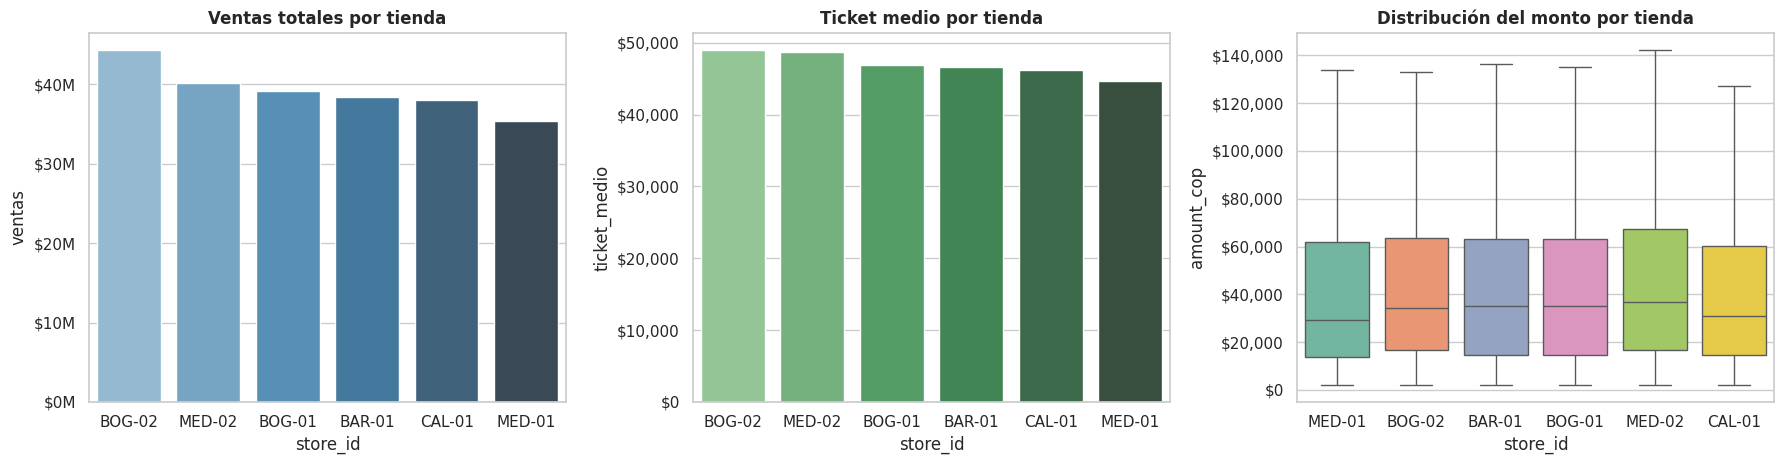

In [19]:
por_tienda = (df.groupby(["ciudad", "store_id"])["amount_cop"]
                .agg(transacciones="count", ventas="sum", ticket_medio="mean", mediana="median")
                .sort_values("ventas", ascending=False))
por_tienda["% ventas"] = por_tienda["ventas"] / por_tienda["ventas"].sum() * 100
display(por_tienda)

fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
v = por_tienda.reset_index()
sns.barplot(data=v, x="store_id", y="ventas", ax=ax[0], palette="Blues_d", hue="store_id", legend=False)
ax[0].set_title("Ventas totales por tienda"); ax[0].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x,_: f"${x/1e6:,.0f}M"))
sns.barplot(data=v, x="store_id", y="ticket_medio", ax=ax[1], palette="Greens_d", hue="store_id", legend=False)
ax[1].set_title("Ticket medio por tienda"); ax[1].yaxis.set_major_formatter(fmt_cop)
sns.boxplot(data=df, x="store_id", y="amount_cop", ax=ax[2], showfliers=False, palette="Set2", hue="store_id", legend=False)
ax[2].set_title("Distribución del monto por tienda"); ax[2].yaxis.set_major_formatter(fmt_cop)
plt.tight_layout(); plt.show()

### 5.3 Método de pago

,transacciones,ventas,ticket_medio,mediana,% transacciones,% ventas
payment_method,,,,,,
Tarjeta,2296,107047299,"46,623.39","33,072.50",45.92,45.47
Efectivo,1486,70127784,"47,192.32","33,785.00",29.72,29.79
App,978,47059223,"48,117.81","35,381.50",19.56,19.99
Bono,240,11210760,"46,711.50","32,100.50",4.80,4.76


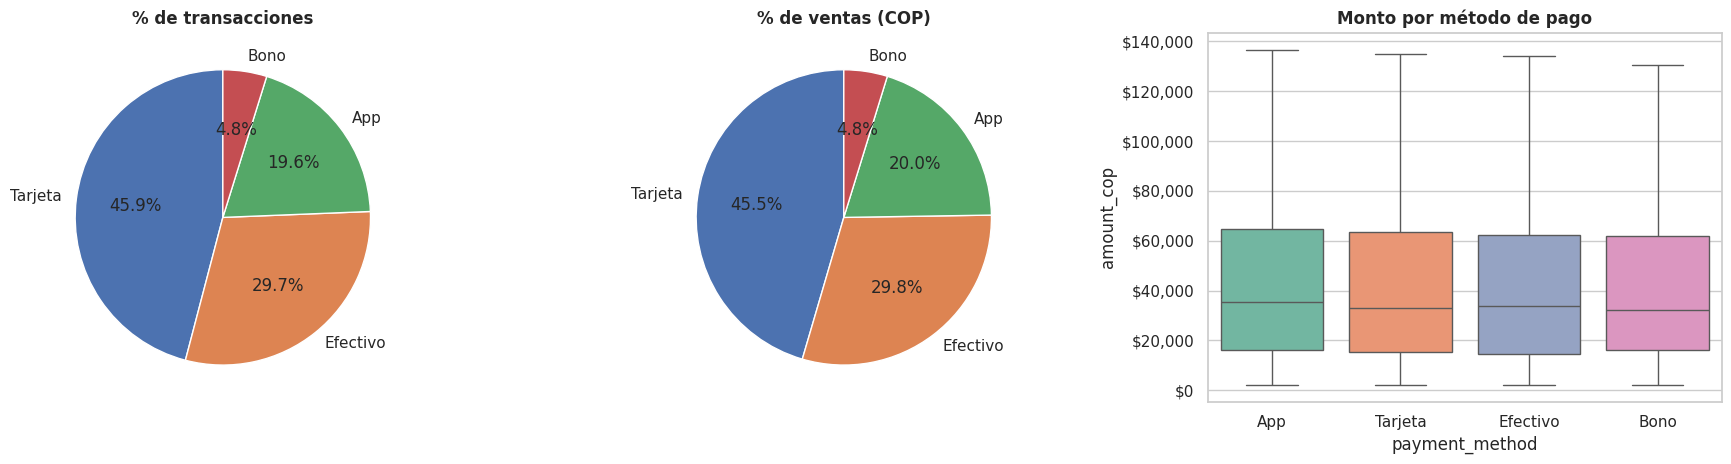

In [20]:
mp = (df.groupby("payment_method")["amount_cop"]
        .agg(transacciones="count", ventas="sum", ticket_medio="mean", mediana="median")
        .sort_values("ventas", ascending=False))
mp["% transacciones"] = mp["transacciones"] / mp["transacciones"].sum() * 100
mp["% ventas"] = mp["ventas"] / mp["ventas"].sum() * 100
display(mp)

fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
df["payment_method"].value_counts().plot.pie(autopct="%1.1f%%", ax=ax[0], startangle=90, ylabel="")
ax[0].set_title("% de transacciones")
mp["ventas"].plot.pie(autopct="%1.1f%%", ax=ax[1], startangle=90, ylabel="")
ax[1].set_title("% de ventas (COP)")
sns.boxplot(data=df, x="payment_method", y="amount_cop", ax=ax[2], showfliers=False, palette="Set2", hue="payment_method", legend=False)
ax[2].set_title("Monto por método de pago"); ax[2].yaxis.set_major_formatter(fmt_cop)
plt.tight_layout(); plt.show()

### 5.4 ¿Los usuarios tienen hábitos? (ciudad, tienda, método de pago y monto)

In [21]:
# Si el usuario eligiera tienda y método de pago al azar en cada compra, ¿qué % usaría más de una?
# Esperado = media sobre usuarios de 1 - Σ pᵢⁿ  (n = nº de compras; pᵢ = peso de cada opción)
def esperado_mas_de_uno(compras, pesos):
    return np.mean([1 - np.sum(np.asarray(p) ** n) for n, p in zip(compras, pesos)])

multi = por_usuario[por_usuario.compras > 1].join(df.drop_duplicates("user_id").set_index("user_id")["ciudad"])
multi["pagos"] = df.groupby("user_id")["payment_method"].nunique()
peso_tienda = df.groupby("ciudad")["store_id"].value_counts(normalize=True)
peso_pago = df["payment_method"].value_counts(normalize=True).values

comp = pd.DataFrame({
    "observado %": [(multi.tiendas > 1).mean() * 100, (multi.pagos > 1).mean() * 100],
    "esperado si fuera al azar %": [
        esperado_mas_de_uno(multi.compras, [peso_tienda[c].values for c in multi.ciudad]) * 100,
        esperado_mas_de_uno(multi.compras, [peso_pago] * len(multi)) * 100]},
    index=["usa más de una tienda", "usa más de un método de pago"])
print(f"Usuarios con 2+ compras: {len(multi)}")
display(comp)

# ¿Cambia el ticket entre usuarios? (solo usuarios con 10+ compras para tener muestra)
grandes = df[df["user_id"].isin(por_usuario[por_usuario.compras >= 10].index)]
h, p = stats.kruskal(*[g["amount_cop"].values for _, g in grandes.groupby("user_id")])
print(f"Kruskal-Wallis monto ~ usuario ({grandes['user_id'].nunique()} usuarios con 10+ compras): H={h:.1f}  p={p:.4f} →",
      "difiere" if p < .05 else "sin diferencia significativa")

Usuarios con 2+ compras: 600


,observado %,esperado si fuera al azar %
usa más de una tienda,49.33,50.64
usa más de un método de pago,93.33,91.77


Kruskal-Wallis monto ~ usuario (135 usuarios con 10+ compras): H=124.0  p=0.7212 → sin diferencia significativa


## 6. Patrones temporales

Días con datos: 31
⚠ Primer día (parcial) empieza a las 08:02:06 | último día (parcial) termina a las 17:59:48
Días completos (29): transacciones/día mín=139, máx=195, media=164.8, desv.=14.0
Días completos fuera del rango 150-190: 6
Tendencia en el tiempo (Spearman): ρ=0.14  p=0.46


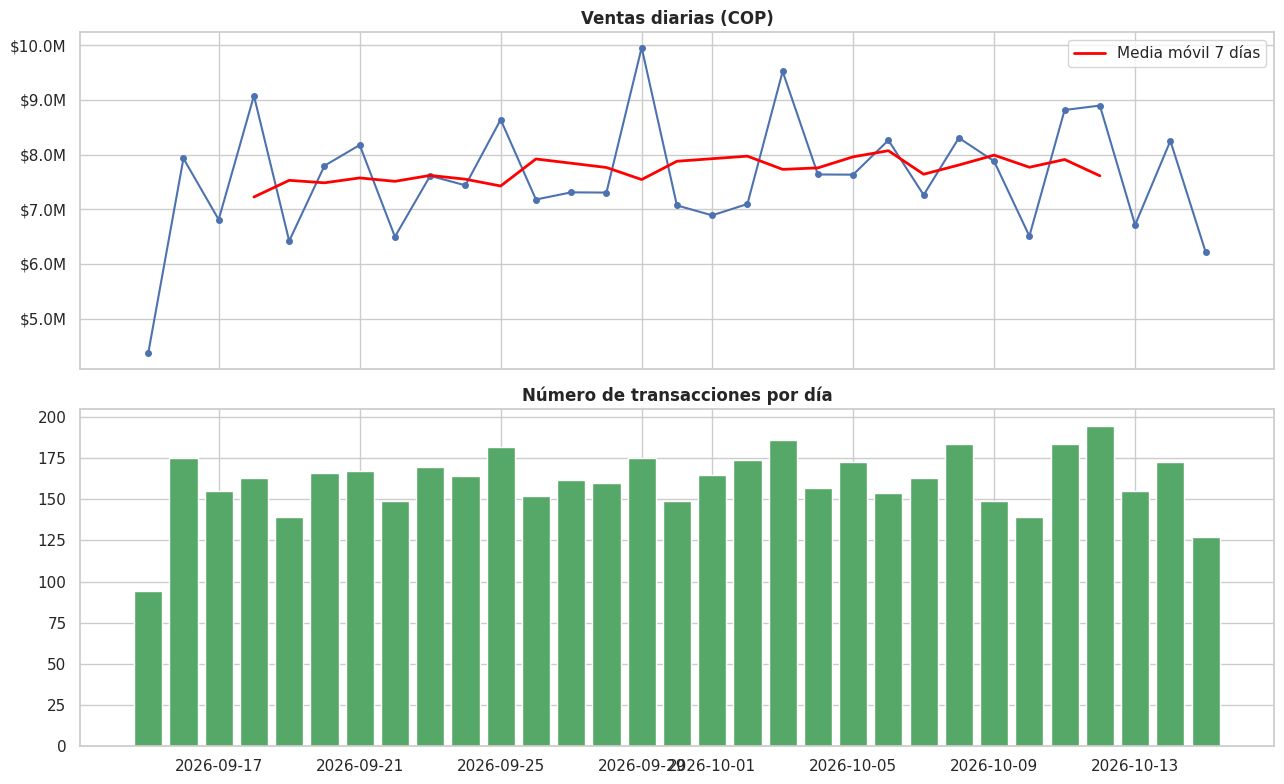

In [22]:
diario = df.groupby("fecha").agg(transacciones=("amount_cop", "size"), ventas=("amount_cop", "sum"), ticket=("amount_cop", "mean"))
print("Días con datos:", len(diario))
print("⚠ Primer día (parcial) empieza a las", df['timestamp'].min().time(), "| último día (parcial) termina a las", df['timestamp'].max().time())

completos = diario.iloc[1:-1]          # sin el primer ni el último día (parciales)
print(f"Días completos ({len(completos)}): transacciones/día mín={completos.transacciones.min()}, máx={completos.transacciones.max()}, "
      f"media={completos.transacciones.mean():.1f}, desv.={completos.transacciones.std():.1f}")
n_fuera = ((completos.transacciones < 150) | (completos.transacciones > 190)).sum()
print(f"Días completos fuera del rango 150-190: {n_fuera}")
rho_t, p_t = stats.spearmanr(np.arange(len(completos)), completos["transacciones"])
print(f"Tendencia en el tiempo (Spearman): ρ={rho_t:.2f}  p={p_t:.2f}")

fig, ax = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
ax[0].plot(diario.index, diario["ventas"], marker="o", ms=4, color="#4C72B0")
ax[0].plot(diario["ventas"].rolling(7, center=True).mean(), color="red", lw=2, label="Media móvil 7 días")
ax[0].set_title("Ventas diarias (COP)"); ax[0].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x,_: f"${x/1e6:,.1f}M")); ax[0].legend()
ax[1].bar(diario.index, diario["transacciones"], color="#55A868")
ax[1].set_title("Número de transacciones por día")
plt.tight_layout(); plt.show()

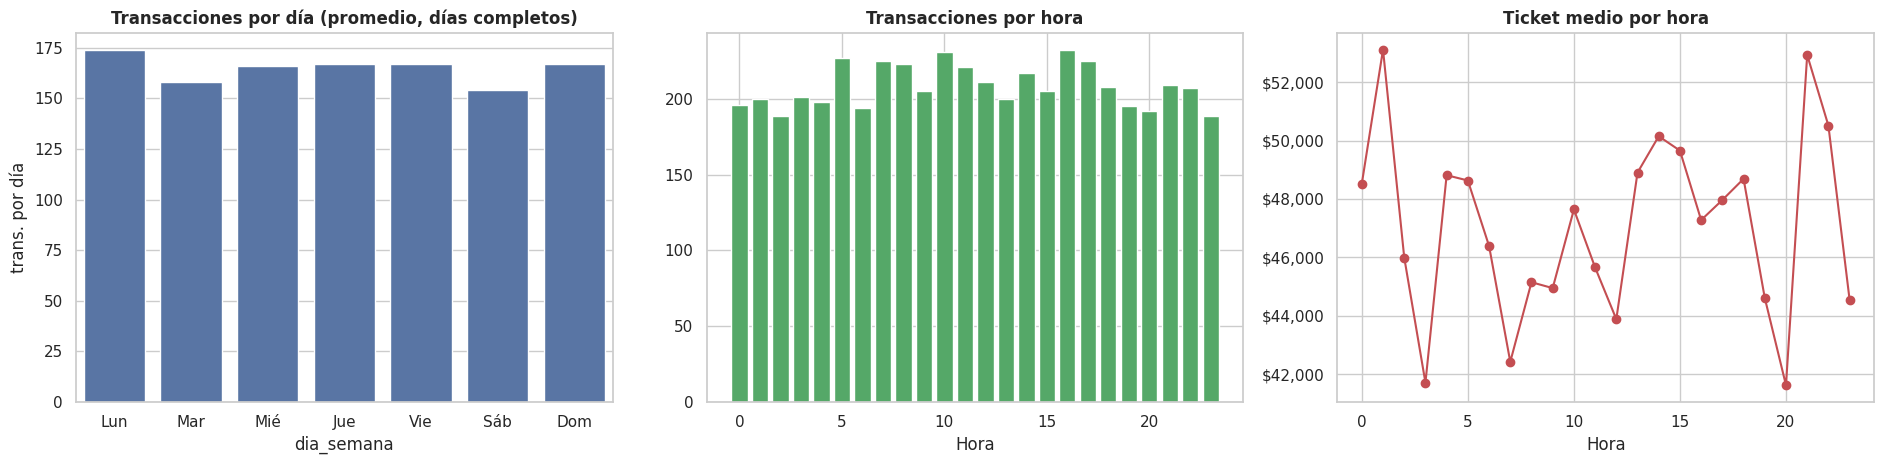

Kruskal-Wallis del nº de transacciones diarias por día de la semana (días completos): H=4.39  p=0.6236 → sin diferencia significativa
Uniformidad por hora: χ²=20.7  p=0.6003 | mín=189 máx=232 transacciones por hora


,n,ventas,ticket,días completos,trans. por día
dia_semana,,,,,
Lun,695,32006408,"46,052.39",4,173.75
Mar,727,35793192,"49,234.10",4,158.25
Mié,830,38120790,"45,928.66",5,166.00
Jue,795,35659099,"44,854.21",4,167.00
Vie,668,32686188,"48,931.42",4,167.00
Sáb,616,29625776,"48,093.79",4,154.00
Dom,669,31553613,"47,165.34",4,167.25


In [23]:
# Día de la semana y hora del día
# Ojo: del mar 15-sep al jue 15-oct, martes/miércoles/jueves aparecen 5 veces y los demás 4. Comparar TOTALES por día
# de la semana sería engañoso, así que se comparan promedios por día usando solo días completos.
dia_de = pd.Series(completos.index.dayofweek.map(dias_es), index=completos.index)

dow = df.groupby("dia_semana", observed=True).agg(n=("amount_cop", "size"), ventas=("amount_cop", "sum"), ticket=("amount_cop", "mean"))
dow["días completos"] = completos.groupby(dia_de.values)["transacciones"].size().reindex(orden_dias).values
dow["trans. por día"] = completos.groupby(dia_de.values)["transacciones"].mean().reindex(orden_dias).values

fig, ax = plt.subplots(1, 3, figsize=(19, 4.8))
sns.barplot(x=dow.index, y=dow["trans. por día"], ax=ax[0], color="#4C72B0"); ax[0].set_title("Transacciones por día (promedio, días completos)")

h = df.groupby("hora").agg(n=("amount_cop","size"), ticket=("amount_cop","mean"))
ax[1].bar(h.index, h["n"], color="#55A868"); ax[1].set_title("Transacciones por hora"); ax[1].set_xlabel("Hora")
ax[2].plot(h.index, h["ticket"], marker="o", color="#C44E52"); ax[2].set_title("Ticket medio por hora")
ax[2].yaxis.set_major_formatter(fmt_cop); ax[2].set_xlabel("Hora")
plt.tight_layout(); plt.show()

kw_h, kw_p = stats.kruskal(*[g["transacciones"].values for _, g in completos.groupby(dia_de.values)])
print(f"Kruskal-Wallis del nº de transacciones diarias por día de la semana (días completos): H={kw_h:.2f}  p={kw_p:.4f} →",
      "difiere" if kw_p < .05 else "sin diferencia significativa")
chi_h, p_h = stats.chisquare(h["n"])
print(f"Uniformidad por hora: χ²={chi_h:.1f}  p={p_h:.4f} | mín={h['n'].min()} máx={h['n'].max()} transacciones por hora")
dow

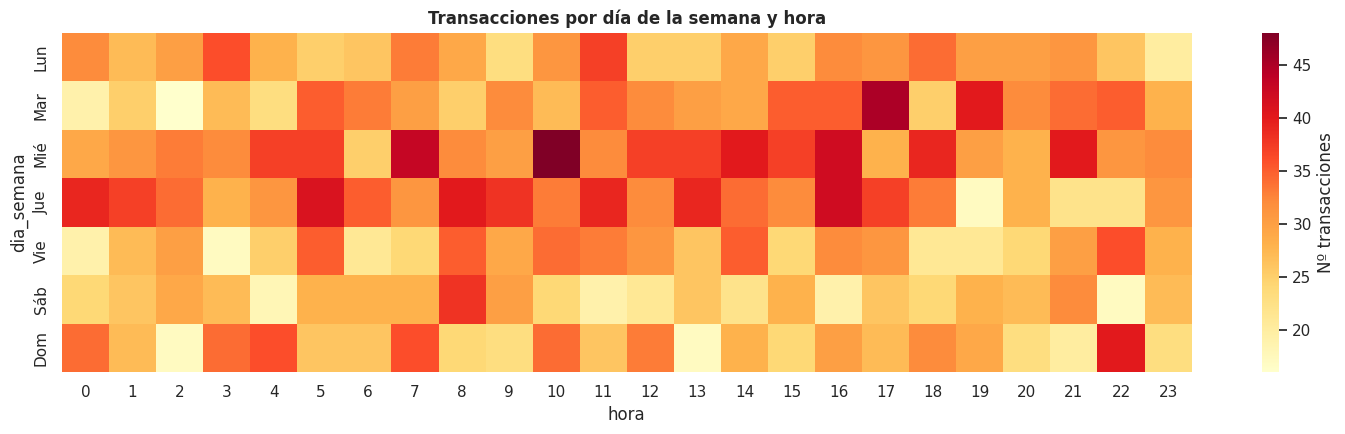

In [24]:
# Mapa de calor día × hora
heat = df.pivot_table(index="dia_semana", columns="hora", values="amount_cop", aggfunc="size", observed=True)
plt.figure(figsize=(15, 4.5))
sns.heatmap(heat, cmap="YlOrRd", annot=False, cbar_kws={"label": "Nº transacciones"})
plt.title("Transacciones por día de la semana y hora"); plt.tight_layout(); plt.show()

In [25]:
# Ventas semanales y por franja horaria
sem = df.groupby("semana").agg(n=("amount_cop","size"), ventas=("amount_cop","sum"))
display(sem)

fr = df.groupby("franja", observed=True).agg(n=("amount_cop","size"), ventas=("amount_cop","sum"), ticket=("amount_cop","mean"))
fr["% ventas"] = fr["ventas"] / fr["ventas"].sum() * 100
fr

,n,ventas
semana,,
2026-09-14,892,42393833
2026-09-21,1146,52843885
2026-09-28,1166,55468500
2026-10-05,1146,54660054
2026-10-12,650,30078794


,n,ventas,ticket,% ventas
franja,,,,
Madrugada (0-5),1211,57913075,"47,822.52",24.60
Mañana (6-11),1299,58918220,"45,356.60",25.02
Tarde (12-17),1290,61860187,"47,953.63",26.27
Noche (18-23),1200,56753584,"47,294.65",24.10


## 7. Cruces entre variables y pruebas estadísticas

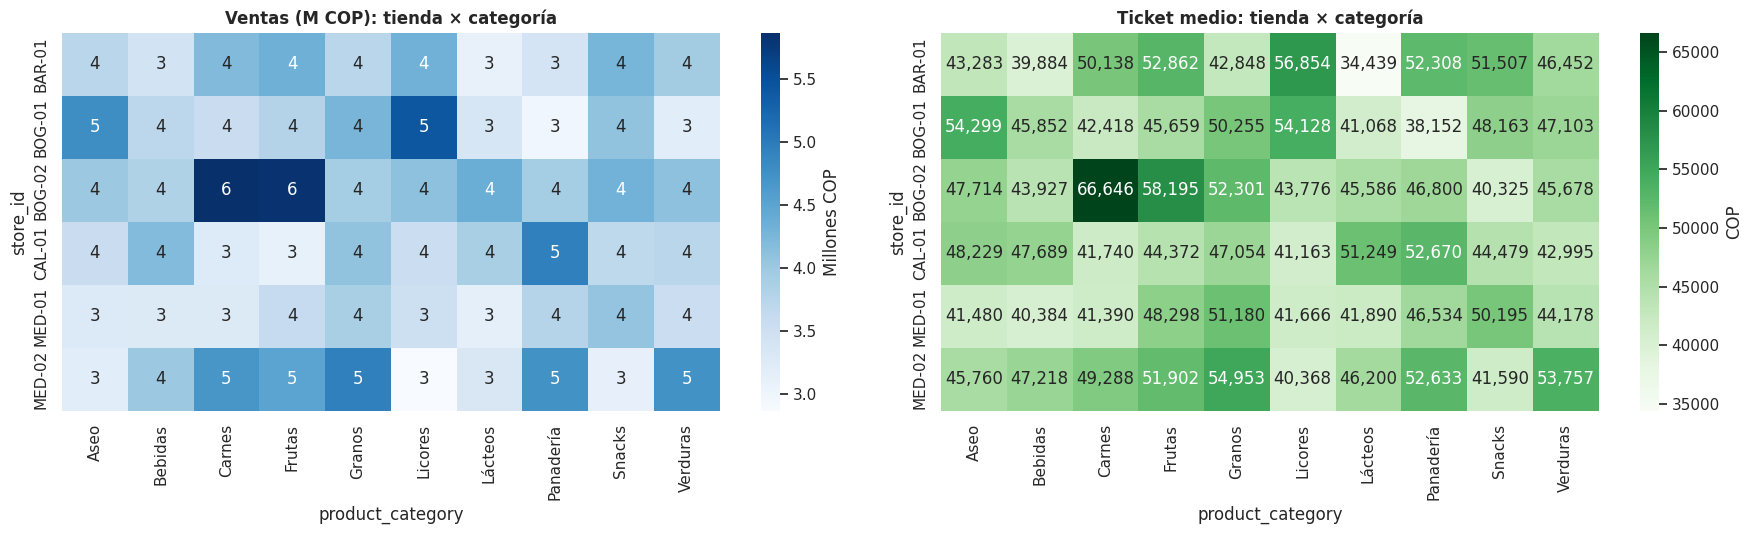

In [26]:
fig, ax = plt.subplots(1, 2, figsize=(18, 5.5))
pv = df.pivot_table(index="store_id", columns="product_category", values="amount_cop", aggfunc="sum") / 1e6
sns.heatmap(pv, annot=True, fmt=".0f", cmap="Blues", ax=ax[0], cbar_kws={"label": "Millones COP"})
ax[0].set_title("Ventas (M COP): tienda × categoría")

pt = df.pivot_table(index="store_id", columns="product_category", values="amount_cop", aggfunc="mean")
sns.heatmap(pt, annot=True, fmt=",.0f", cmap="Greens", ax=ax[1], cbar_kws={"label": "COP"})
ax[1].set_title("Ticket medio: tienda × categoría")
plt.tight_layout(); plt.show()

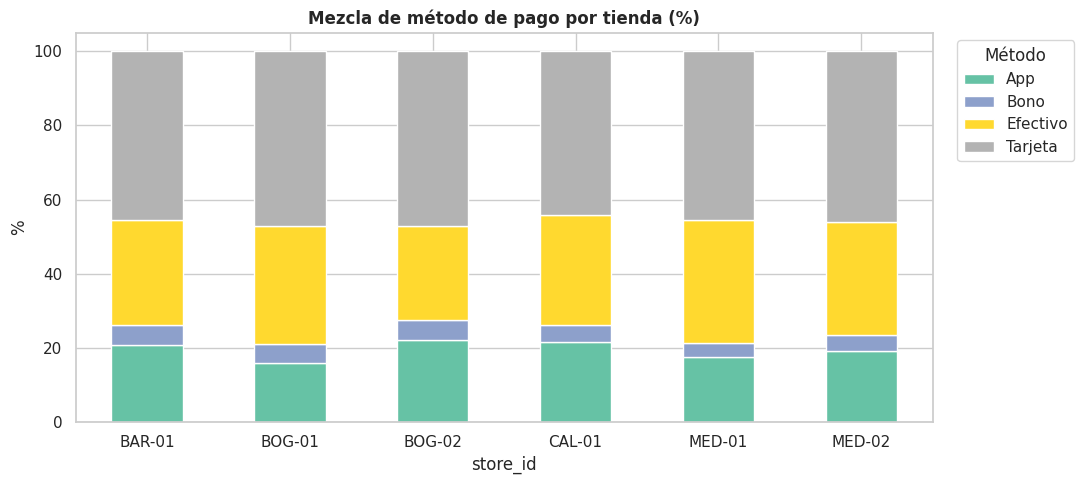

payment_method,App,Bono,Efectivo,Tarjeta
store_id,,,,
BAR-01,20.87,5.34,28.40,45.39
BOG-01,15.95,5.04,32.01,47.00
BOG-02,21.99,5.52,25.41,47.07
CAL-01,21.63,4.50,29.65,44.23
MED-01,17.57,3.79,33.12,45.51
MED-02,19.08,4.50,30.26,46.17


In [27]:
# Método de pago por tienda (% por fila)
ct = pd.crosstab(df["store_id"], df["payment_method"], normalize="index") * 100
ax = ct.plot.bar(stacked=True, figsize=(11, 5), colormap="Set2")
ax.set_title("Mezcla de método de pago por tienda (%)"); ax.set_ylabel("%"); plt.xticks(rotation=0)
plt.legend(title="Método", bbox_to_anchor=(1.02, 1)); plt.tight_layout(); plt.show()
ct

In [28]:
# Pruebas de hipótesis
print("── ¿Hay asociación entre variables categóricas? (Chi-cuadrado de independencia) ──")
for a, b in [("store_id","product_category"), ("store_id","payment_method"), ("product_category","payment_method")]:
    chi, p, dof, _ = stats.chi2_contingency(pd.crosstab(df[a], df[b]))
    print(f"{a:18s} × {b:18s} χ²={chi:7.1f} gl={dof:3d} p={p:.4f} →", "asociadas" if p < .05 else "independientes")

print("\n── ¿El monto difiere entre grupos? (Kruskal-Wallis, no paramétrico) ──")
for c in ["store_id", "product_category", "payment_method", "dia_semana", "franja"]:
    grupos = [g["amount_cop"].values for _, g in df.groupby(c, observed=True)]
    h, p = stats.kruskal(*grupos)
    print(f"{c:18s} H={h:7.2f} p={p:.4f} →", "difiere" if p < .05 else "sin diferencia significativa")

print("\n── Fin de semana vs entre semana (Mann-Whitney) ──")
u, p = stats.mannwhitneyu(df.loc[df.es_fin_semana, "amount_cop"], df.loc[~df.es_fin_semana, "amount_cop"])
print(f"p={p:.4f}")

── ¿Hay asociación entre variables categóricas? (Chi-cuadrado de independencia) ──
store_id           × product_category   χ²=   35.5 gl= 45 p=0.8441 → independientes
store_id           × payment_method     χ²=   27.9 gl= 15 p=0.0219 → asociadas
product_category   × payment_method     χ²=   28.9 gl= 27 p=0.3655 → independientes

── ¿El monto difiere entre grupos? (Kruskal-Wallis, no paramétrico) ──
store_id           H=  10.81 p=0.0554 → sin diferencia significativa
product_category   H=  11.11 p=0.2684 → sin diferencia significativa
payment_method     H=   1.05 p=0.7891 → sin diferencia significativa
dia_semana         H=   3.81 p=0.7020 → sin diferencia significativa
franja             H=   0.27 p=0.9657 → sin diferencia significativa

── Fin de semana vs entre semana (Mann-Whitney) ──
p=0.6213


## 8. Conclusiones de la Parte 1

> Los hallazgos de abajo corresponden a la ejecución sobre este archivo; si cambias los datos, vuelve a revisarlos.

### Calidad de datos
- **Estructura limpia:** 5.000 filas, 7 columnas (incluye `user_id`), 0 nulos, 0 IDs de transacción duplicados, 0 montos ≤ 0, 6 tiendas, 10 categorías y 4 métodos de pago.
- **Defecto de codificación:** las 983 filas de `Lácteos` (491) y `Panadería` (492) traen la categoría con texto dañado (`LÃ¡cteos`, `PanaderÃ­a`). `nunique()` no lo detecta porque siguen siendo 10 valores. El notebook lo repara en la sección 2, pero conviene corregirlo en el origen: sin reparación esas dos categorías no coinciden con las del JSON.
- Hay **5 timestamps repetidos** (pares de transacciones en el mismo segundo), todos de usuarios distintos. En 3 pares difieren tienda y categoría, en 1 par cambia solo la categoría (BOG-01) y en 1 par coinciden tienda y categoría (CAL-01, Bebidas). Son plausibles, no errores.
- **Cobertura temporal:** 15-sep-2026 a 15-oct-2026 (31 días). El primer y el último día son parciales (08:02 y 17:59), por lo que no conviene compararlos con días completos.
- **Dato llamativo:** hay transacciones en **todas las horas del día**, con una distribución casi plana (entre 189 y 232 por hora; χ² frente a uniforme p = 0,60) e incluso ~24,6 % de las ventas entre 0 y 5 h. Es raro para comercio físico; conviene confirmar si los `timestamp` están en UTC, si hay ventas 24/7 o si es una variable generada/sintética.

### Monto (`amount_cop`)
- Ventas totales ≈ **$235,4 M COP**; ticket medio **$47.089**, mediana **$33.650**.
- Distribución **asimétrica a la derecha** (asimetría 1,93; CV 0,94): la media supera a la mediana y no es normal ni log-normal exacta (Shapiro rechaza ambas), aunque el log acerca mucho la forma.
- El **5,2 % de las transacciones** supera el límite IQR ($135.029) y concentra el **19,7 % de las ventas**. Máximo: $413.280. No parecen errores sino compras grandes, pero vale la pena revisarlas.

### Usuarios (`user_id`)
- **672 usuarios** para 5.000 transacciones; 600 (89,3 %) compran 2 o más veces. La mediana es 5 compras, la media 7,4 y el máximo 128 (`usr_6260`, ~4 compras por día).
- **Concentración moderada:** los 10 usuarios más activos suman el 14,8 % de las transacciones (14,4 % de las ventas) y el 5 % más activo (33 usuarios) el 28,6 % (28,1 % de las ventas).
- **Cada usuario compra en una sola ciudad** (0 de 672 aparecen en más de una). Los usuarios se reparten parejo entre ciudades (157-180), pero Bogotá y Medellín, que tienen dos tiendas, registran ~9,7-9,9 compras por usuario frente a ~4,8-5,2 en Barranquilla y Cali.
- **Dentro de su ciudad, el usuario no muestra hábitos:** el 49,3 % de los usuarios con 2+ compras usa más de una tienda (esperado al azar: 50,6 %) y el 93,3 % usa más de un método de pago (esperado: 91,8 %). Tampoco hay diferencias de ticket entre los 135 usuarios con 10+ compras (Kruskal p = 0,72).

### Tiendas, categorías y pagos
- **Tiendas:** BOG-02 lidera (905 trans., 18,8 % de ventas) y MED-01 es la más baja (791, 15,0 %). Aun así, el reparto de transacciones entre tiendas es compatible con uniforme (p = 0,12) y el monto no difiere de forma significativa (Kruskal p = 0,055, en el límite).
- **Categorías:** prácticamente balanceadas (~10 % cada una). Frutas, Granos y Carnes lideran en ventas; Lácteos y Bebidas tienen el ticket más bajo, pero las diferencias de monto **no son significativas** (p = 0,27).
- **Método de pago:** el único desbalanceado: Tarjeta 45,9 %, Efectivo 29,7 %, App 19,6 %, Bono 4,8 %. El ticket es similar entre métodos (p = 0,79), y el % de ventas casi coincide con el % de transacciones.
- La mezcla de pagos **sí varía por tienda** (χ² p = 0,02): p. ej. BOG-02 y CAL-01 usan más App (~22 %), mientras BOG-01 y MED-01 tienen más efectivo (~32-33 %).

### Tiempo
- **Volumen diario estable:** en los 29 días completos hay entre 139 y 195 transacciones por día (media 164,8; 6 días quedan fuera del rango 150-190), sin tendencia (Spearman ρ = 0,14; p = 0,46).
- **Día de la semana:** los totales (miércoles 830, sábado 616) engañan, porque entre el 15-sep y el 15-oct martes, miércoles y jueves aparecen 5 veces y los demás 4. Con promedios por día completo los valores van de 154 (sábado) a 174 (lunes) y no hay diferencia significativa (Kruskal p = 0,62). Tampoco difiere el monto por día (p = 0,70) ni entre fin de semana y entre semana (p = 0,62).
- No hay franja horaria dominante: las cuatro franjas aportan entre 24 % y 26 % de las ventas.

### Lectura general y siguientes pasos
Salvo la codificación, los datos están limpios pero muestran **poca estructura de comportamiento**: casi todas las variables son estadísticamente independientes entre sí. Las excepciones son la mezcla de pago por tienda (p = 0,02) y la estructura de `user_id` (cada usuario pertenece a una ciudad y hay clientes muy frecuentes); el efecto tienda sobre el monto queda en el límite (p = 0,055) y no es significativo. Dentro de su ciudad, los usuarios eligen tienda y método de pago como si fuera al azar. Esto, junto con la actividad 24 h, sugiere que podrían ser datos simulados. Pasos recomendados:
1. Corregir en el origen la codificación de `Lácteos` y `Panadería`.
2. Confirmar la zona horaria y el horario real de operación de las tiendas.
3. Investigar las compras > $135 mil (¿mayoristas, errores de digitación?) y a los usuarios más activos (`usr_6260`, `usr_3632`, `usr_7358`: ¿cuentas institucionales?).
4. Añadir producto/SKU, cantidades y atributos del cliente para poder segmentar y modelar; con `user_id` ya es posible un RFM básico, pero con tan poca variación entre usuarios dará segmentos poco diferenciados.
5. Si hay más de un mes de historia, repetir el análisis para ver estacionalidad (quincena, fin de mes, festivos).

---
# PARTE 2 — Logs de e-commerce (JSON)

Eventos de navegación y compra: `event_id`, `timestamp`, `user_id`, `event_type`, `device`, `product_category`, `session_duration_sec`.

> **Nota:** esta parte se rehízo para el archivo `ecommerce_logs_5000.json` actual. A diferencia de la versión anterior (eventos de varios tipos repartidos en todo 2026, con categorías en inglés), este archivo contiene **solo eventos `purchase`**, en la misma ventana que el POS y con las mismas categorías, así que el análisis de embudo ya no aplica y el foco pasa a ser el **cruce con el POS**.

## 9. Carga y calidad de datos

In [29]:
logs = pd.read_json("ecommerce_logs_5000.json")

# El timestamp viene en UTC (sufijo "Z"); lo dejamos como fecha-hora sin zona para poder compararlo con el POS
logs["timestamp"] = pd.to_datetime(logs["timestamp"], utc=True).dt.tz_localize(None)

print(f"Filas: {len(logs):,} | Columnas: {logs.shape[1]}")
logs.head(10)

Filas: 5,000 | Columnas: 7


,event_id,timestamp,user_id,event_type,device,product_category,session_duration_sec
0,evt_00001,2026-09-15 08:02:06,usr_2939,purchase,mobile,Snacks,886
1,evt_00002,2026-09-15 08:02:39,usr_9520,purchase,desktop,Frutas,1301
2,evt_00003,2026-09-15 08:06:44,usr_6406,purchase,desktop,Bebidas,1553
3,evt_00004,2026-09-15 08:15:17,usr_9223,purchase,tablet,Panadería,272
4,evt_00005,2026-09-15 08:39:12,usr_3245,purchase,tablet,Lácteos,1178
5,evt_00006,2026-09-15 08:46:15,usr_3807,purchase,tablet,Panadería,486
6,evt_00007,2026-09-15 08:50:51,usr_2836,purchase,desktop,Lácteos,1237
7,evt_00008,2026-09-15 08:54:27,usr_8562,purchase,mobile,Licores,903
8,evt_00009,2026-09-15 09:08:58,usr_2479,purchase,tablet,Licores,491
9,evt_00010,2026-09-15 09:28:07,usr_2763,purchase,tablet,Carnes,665


In [30]:
calidad_logs = pd.DataFrame({"nulos": logs.isna().sum(), "únicos": logs.nunique()})
display(calidad_logs)

print("event_id duplicados:        ", logs["event_id"].duplicated().sum())
print("Filas duplicadas completas: ", logs.duplicated().sum())
print("Formato event_id (evt_#####):", logs["event_id"].str.fullmatch(r"evt_\d{5}").all())
print("Formato user_id (usr_####):  ", logs["user_id"].str.fullmatch(r"usr_\d{4}").all())
print("Duración <= 0:              ", (logs["session_duration_sec"] <= 0).sum())
print("Rango de fechas:", logs["timestamp"].min(), "→", logs["timestamp"].max())
print("Ordenado cronológicamente:  ", logs["timestamp"].is_monotonic_increasing)
print("Texto con codificación dañada:", int(logs["product_category"].str.contains("Ã", regex=False).sum()))
for c in ["event_type", "device", "product_category"]:
    print(f"{c:17s}", sorted(logs[c].unique()))

,nulos,únicos
event_id,0,5000
timestamp,0,4995
user_id,0,672
event_type,0,1
device,0,3
product_category,0,10
session_duration_sec,0,1688


event_id duplicados:         0
Filas duplicadas completas:  0
Formato event_id (evt_#####): True
Formato user_id (usr_####):   True
Duración <= 0:               0
Rango de fechas: 2026-09-15 08:02:06 → 2026-10-15 17:59:48
Ordenado cronológicamente:   True
Texto con codificación dañada: 0
event_type        ['purchase']
device            ['desktop', 'mobile', 'tablet']
product_category  ['Aseo', 'Bebidas', 'Carnes', 'Frutas', 'Granos', 'Licores', 'Lácteos', 'Panadería', 'Snacks', 'Verduras']


## 10. Cruce con las transacciones (POS)
Llave de cruce: `(timestamp, user_id)`. Si ambas fuentes describen los mismos hechos, cada evento debería tener su transacción.

In [31]:
llave_unica_pos = not df.duplicated(["timestamp", "user_id"]).any()
llave_unica_log = not logs.duplicated(["timestamp", "user_id"]).any()
print("Llave (timestamp, user_id) única →  POS:", llave_unica_pos, "| logs:", llave_unica_log)

m = df.merge(logs, on=["timestamp", "user_id"], how="outer", suffixes=("_pos", "_log"), indicator=True)
print("Resultado del cruce (ambos / solo POS / solo logs):", m["_merge"].value_counts().to_dict())
print(f"Categoría idéntica en POS y log: {(m['product_category_pos'] == m['product_category_log']).mean():.1%}")
print("Mismas categorías en ambas fuentes:", set(df["product_category"]) == set(logs["product_category"]))

# ¿Además van en el mismo orden? evt_00001 ↔ TXN10000, evt_00002 ↔ TXN10001, ...
n_evt = logs["event_id"].str[4:].astype(int)
n_txn = df["transaction_id"].str[3:].astype(int)
print("evt_N corresponde a TXN(10000+N-1) en todas las filas:", bool((n_evt + 9999 == n_txn).all()))
print("event_type distintos en los logs:", logs["event_type"].value_counts().to_dict())

# Dataset unificado: cada transacción del POS + el dispositivo y la duración de su sesión
cruce = df.merge(logs[["timestamp", "user_id", "event_id", "device", "session_duration_sec"]],
                 on=["timestamp", "user_id"], how="left", validate="one_to_one")
print("\nTransacciones sin evento asociado:", cruce["device"].isna().sum(), "| filas del dataset unificado:", len(cruce))
cruce[["transaction_id", "event_id", "timestamp", "user_id", "store_id", "product_category", "amount_cop", "payment_method", "device", "session_duration_sec"]].head()

Llave (timestamp, user_id) única →  POS: True | logs: True
Resultado del cruce (ambos / solo POS / solo logs): {'both': 5000, 'left_only': 0, 'right_only': 0}
Categoría idéntica en POS y log: 100.0%
Mismas categorías en ambas fuentes: True
evt_N corresponde a TXN(10000+N-1) en todas las filas: True
event_type distintos en los logs: {'purchase': 5000}

Transacciones sin evento asociado: 0 | filas del dataset unificado: 5000


,transaction_id,event_id,timestamp,user_id,store_id,product_category,amount_cop,payment_method,device,session_duration_sec
0,TXN10000,evt_00001,2026-09-15 08:02:06,usr_2939,MED-01,Snacks,74979,App,mobile,886
1,TXN10001,evt_00002,2026-09-15 08:02:39,usr_9520,BOG-02,Frutas,62048,App,desktop,1301
2,TXN10002,evt_00003,2026-09-15 08:06:44,usr_6406,BAR-01,Bebidas,17878,App,desktop,1553
3,TXN10003,evt_00004,2026-09-15 08:15:17,usr_9223,BOG-01,Panadería,4715,Tarjeta,tablet,272
4,TXN10004,evt_00005,2026-09-15 08:39:12,usr_3245,MED-02,Lácteos,8920,Efectivo,tablet,1178


## 11. Análisis univariado de los logs

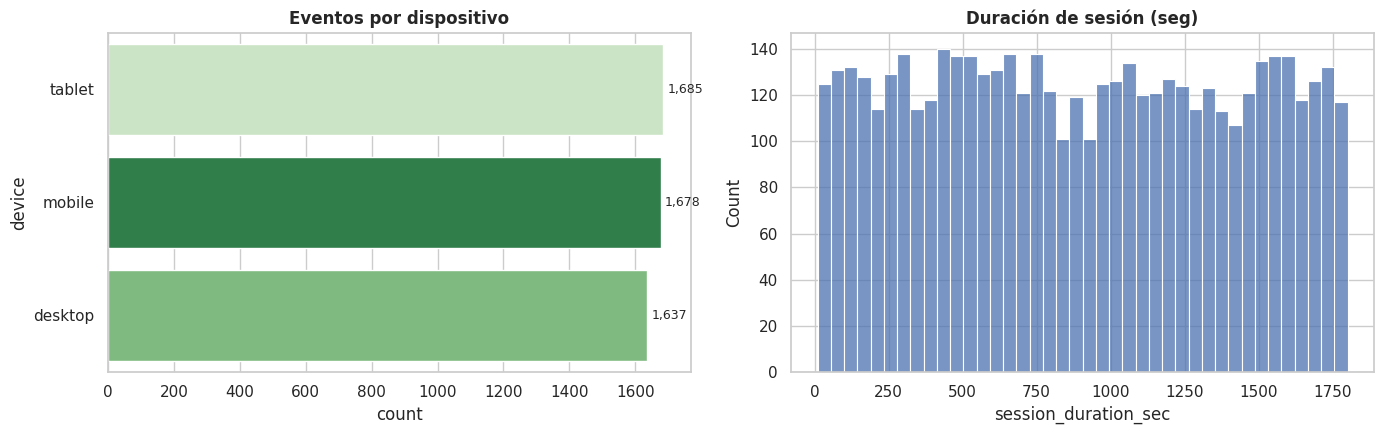

Dispositivo, ¿uniforme? χ²=0.81  p=0.6680 → compatible con uniforme
{'tablet': 33.7, 'mobile': 33.6, 'desktop': 32.7}


,session_duration_sec
count,"5,000.00"
mean,898.24
std,519.23
min,10.00
10%,183.90
25%,452.00
50%,892.00
75%,"1,350.00"
90%,"1,619.00"
max,"1,800.00"


Asimetría: 0.028 | sesiones < 60 s: 143
KS vs uniforme[10, 1800]: D=0.0155  p=0.1766 → compatible con uniforme


In [32]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
orden_dev = logs["device"].value_counts().index
sns.countplot(data=logs, y="device", order=orden_dev, ax=ax[0], palette="Greens_r", hue="device", legend=False)
ax[0].set_title("Eventos por dispositivo")
for p in ax[0].patches:
    ax[0].annotate(f"{int(p.get_width()):,}", (p.get_width(), p.get_y() + p.get_height()/2), va="center", ha="left", fontsize=9, xytext=(3, 0), textcoords="offset points")

sns.histplot(logs["session_duration_sec"], bins=40, ax=ax[1], color="#4C72B0"); ax[1].set_title("Duración de sesión (seg)")
plt.tight_layout(); plt.show()

chi, p = stats.chisquare(logs["device"].value_counts())
print(f"Dispositivo, ¿uniforme? χ²={chi:.2f}  p={p:.4f} →", "NO uniforme" if p < .05 else "compatible con uniforme")
print(logs["device"].value_counts(normalize=True).mul(100).round(1).to_dict())

display(logs["session_duration_sec"].describe(percentiles=[.1, .25, .5, .75, .9]).to_frame())
print("Asimetría:", round(logs["session_duration_sec"].skew(), 3), "| sesiones < 60 s:", (logs["session_duration_sec"] < 60).sum())

# ¿La duración se parece a una uniforme entre su mínimo y máximo?
mn, mx = logs["session_duration_sec"].agg(["min", "max"])
ks = stats.kstest((logs["session_duration_sec"] - mn) / (mx - mn), "uniform")
print(f"KS vs uniforme[{mn}, {mx}]: D={ks.statistic:.4f}  p={ks.pvalue:.4f} →", "se rechaza la uniforme" if ks.pvalue < .05 else "compatible con uniforme")

## 12. Dispositivo y duración de sesión frente a las variables del POS

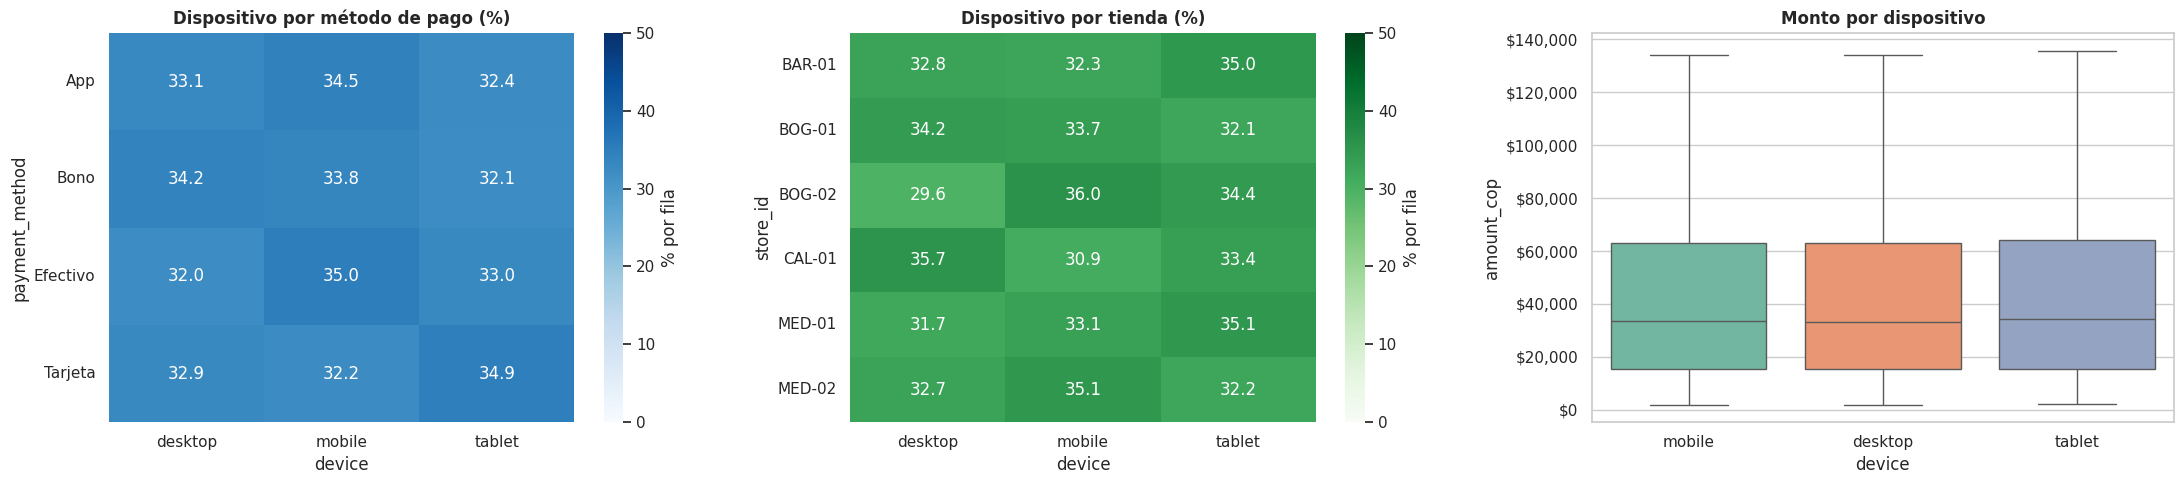

── ¿El dispositivo se asocia con variables del POS? (chi-cuadrado de independencia) ──
  device × payment_method    χ²=   4.7 gl= 6 p=0.5892 → independientes
  device × store_id          χ²=  12.3 gl=10 p=0.2629 → independientes
  device × product_category  χ²=  22.1 gl=18 p=0.2264 → independientes

Kruskal-Wallis monto ~ dispositivo: H=0.22  p=0.8952 → sin diferencia significativa


,transacciones,ventas,ticket_medio,mediana,% ventas
device,,,,,
tablet,1685,81277687,"48,236.02","34,166.00",34.52
mobile,1678,78685317,"46,892.32","33,711.50",33.42
desktop,1637,75482062,"46,110.00","33,125.00",32.06


In [33]:
fig, ax = plt.subplots(1, 3, figsize=(22, 5))
# Escala fija 0-50 %: así las diferencias de 2-3 puntos se ven como lo que son (casi uniforme: ~33 % por dispositivo)
sns.heatmap(pd.crosstab(cruce["payment_method"], cruce["device"], normalize="index") * 100, annot=True, fmt=".1f", cmap="Blues", ax=ax[0],
            vmin=0, vmax=50, cbar_kws={"label": "% por fila"}); ax[0].set_title("Dispositivo por método de pago (%)")
sns.heatmap(pd.crosstab(cruce["store_id"], cruce["device"], normalize="index") * 100, annot=True, fmt=".1f", cmap="Greens", ax=ax[1],
            vmin=0, vmax=50, cbar_kws={"label": "% por fila"}); ax[1].set_title("Dispositivo por tienda (%)")
for a in ax[:2]:
    a.tick_params(axis="y", rotation=0)
sns.boxplot(data=cruce, x="device", y="amount_cop", ax=ax[2], showfliers=False, palette="Set2", hue="device", legend=False)
ax[2].set_title("Monto por dispositivo"); ax[2].yaxis.set_major_formatter(fmt_cop)
plt.tight_layout(w_pad=3); plt.show()

print("── ¿El dispositivo se asocia con variables del POS? (chi-cuadrado de independencia) ──")
for b in ["payment_method", "store_id", "product_category"]:
    chi, p, dof, _ = stats.chi2_contingency(pd.crosstab(cruce["device"], cruce[b]))
    print(f"  device × {b:17s} χ²={chi:6.1f} gl={dof:2d} p={p:.4f} →", "asociadas" if p < .05 else "independientes")

h, p = stats.kruskal(*[g["amount_cop"].values for _, g in cruce.groupby("device")])
print(f"\nKruskal-Wallis monto ~ dispositivo: H={h:.2f}  p={p:.4f} →", "difiere" if p < .05 else "sin diferencia significativa")

(cruce.groupby("device").agg(transacciones=("amount_cop", "size"), ventas=("amount_cop", "sum"), ticket_medio=("amount_cop", "mean"), mediana=("amount_cop", "median"))
      .assign(**{"% ventas": lambda t: t["ventas"] / t["ventas"].sum() * 100}).sort_values("ventas", ascending=False))

── ¿La duración de sesión difiere entre grupos? (Kruskal-Wallis) ──
  device            H=  2.39 p=0.3025 → sin diferencia significativa
  store_id          H=  4.04 p=0.5435 → sin diferencia significativa
  payment_method    H=  1.91 p=0.5922 → sin diferencia significativa
  product_category  H= 12.60 p=0.1818 → sin diferencia significativa
  dia_semana        H=  6.57 p=0.3621 → sin diferencia significativa
  franja            H=  4.37 p=0.2246 → sin diferencia significativa
  (umbral Bonferroni para 6 pruebas: p < 0.0083; menor p observado = 0.1818)

Spearman duración ~ monto: ρ=0.012  p=0.388
Spearman duración ~ hora:  ρ=0.008  p=0.563


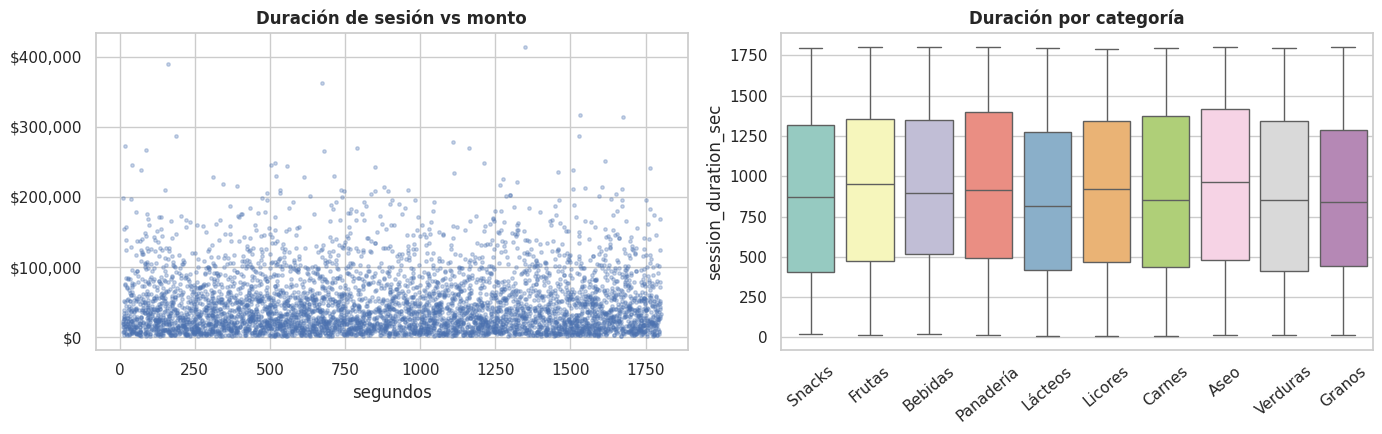

In [34]:
# Duración de sesión: ¿depende de algo del POS?
print("── ¿La duración de sesión difiere entre grupos? (Kruskal-Wallis) ──")
pruebas = ["device", "store_id", "payment_method", "product_category", "dia_semana", "franja"]
pv = []
for c in pruebas:
    h, p = stats.kruskal(*[g["session_duration_sec"].values for _, g in cruce.groupby(c, observed=True)])
    pv.append(p)
    print(f"  {c:17s} H={h:6.2f} p={p:.4f} →", "difiere" if p < .05 else "sin diferencia significativa")
print(f"  (umbral Bonferroni para {len(pruebas)} pruebas: p < {0.05 / len(pruebas):.4f}; menor p observado = {min(pv):.4f})")

r1, p1 = stats.spearmanr(cruce["session_duration_sec"], cruce["amount_cop"])
r2, p2 = stats.spearmanr(cruce["session_duration_sec"], cruce["hora"])
print(f"\nSpearman duración ~ monto: ρ={r1:.3f}  p={p1:.3f}")
print(f"Spearman duración ~ hora:  ρ={r2:.3f}  p={p2:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].scatter(cruce["session_duration_sec"], cruce["amount_cop"], s=6, alpha=.3, color="#4C72B0")
ax[0].set_title("Duración de sesión vs monto"); ax[0].set_xlabel("segundos"); ax[0].yaxis.set_major_formatter(fmt_cop)
sns.boxplot(data=cruce, x="product_category", y="session_duration_sec", ax=ax[1], palette="Set3", hue="product_category", legend=False)
ax[1].set_title("Duración por categoría"); ax[1].tick_params(axis="x", rotation=40); ax[1].set_xlabel("")
plt.tight_layout(); plt.show()

## 13. Dispositivo por usuario

In [35]:
# Un usuario real suele repetir dispositivo. Si el dispositivo se asignara al azar en cada compra,
# ¿qué % de usuarios con 2+ compras usaría más de uno? (esperado = media de 1 - Σ pᵢⁿ)
u_dev = cruce.groupby("user_id").agg(compras=("amount_cop", "size"), dispositivos=("device", "nunique"))
multi_d = u_dev[u_dev.compras > 1]
peso_dev = cruce["device"].value_counts(normalize=True).values
esperado = np.mean([1 - np.sum(peso_dev ** n) for n in multi_d.compras])
print(f"Usuarios con 2+ compras: {len(multi_d)}")
print(f"Usan más de un dispositivo → observado: {(multi_d.dispositivos > 1).mean():.1%} | esperado si fuera al azar: {esperado:.1%}")
print("Distribución de nº de dispositivos por usuario (2+ compras):", multi_d["dispositivos"].value_counts().sort_index().to_dict())

# Pagos en efectivo con sesión online
ef = cruce[cruce["payment_method"] == "Efectivo"]
print(f"\nCompras pagadas en efectivo que tienen sesión online asociada: {len(ef):,} ({len(ef) / len(cruce):.1%} del total)")

Usuarios con 2+ compras: 600
Usan más de un dispositivo → observado: 93.2% | esperado si fuera al azar: 92.6%
Distribución de nº de dispositivos por usuario (2+ compras): {1: 41, 2: 208, 3: 351}

Compras pagadas en efectivo que tienen sesión online asociada: 1,486 (29.7% del total)


## 14. Conclusiones de la Parte 2

> Esta parte se rehízo para el `ecommerce_logs_5000.json` actual; sus cifras **no son comparables** con las de la versión anterior del notebook (que analizaba otro archivo con varios tipos de evento, fechas de todo 2026 y categorías en inglés).

**Calidad de datos**
- 5.000 eventos de 672 usuarios, sin nulos, sin `event_id` ni filas duplicadas y con formatos de ID consistentes. Van ordenados cronológicamente y cubren exactamente la misma ventana que el POS (15-sep 08:02:06 → 15-oct 17:59:48).
- **`event_type` solo tiene un valor: `purchase`** (5.000 de 5.000). El archivo no contiene navegación, búsquedas ni carritos.
- Las categorías son las mismas 10 del POS (en español); ya no hay fechas posteriores al corte ni categorías en inglés.

**Relación con el POS**
- La llave `(timestamp, user_id)` es única en ambas fuentes y el cruce da **5.000 de 5.000 coincidencias**, sin huérfanos. La categoría coincide en el **100 %** (una vez reparada la codificación del CSV) y `evt_N` corresponde a `TXN(10000+N−1)` en todas las filas.
- Es decir, **cada evento es la traza de una transacción del POS**; los logs no aportan compras adicionales ni eventos previos a la compra. Lo único nuevo son dos columnas: `device` y `session_duration_sec`.
- Los timestamps coinciden **al segundo** con el POS pero el JSON los declara en UTC (sufijo `Z`) y el CSV no indica zona. O el POS también está en UTC, o la etiqueta es incorrecta, o los logs se generaron a partir del POS. Hay que confirmarlo.

**Dispositivo y duración de sesión**
- Reparto casi exacto en tercios: tablet 33,7 %, mobile 33,6 %, desktop 32,7 % (compatible con uniforme, p = 0,67).
- El dispositivo es **independiente** de método de pago (p = 0,59), tienda (p = 0,26) y categoría (p = 0,23), y el monto no cambia por dispositivo (p = 0,90). Las ventas se reparten 34,5 % tablet, 33,4 % mobile y 32,1 % desktop.
- La duración va de 10 a 1.800 s (media 898, mediana 892, asimetría 0,03) y es **compatible con una uniforme** (KS p = 0,18). 143 sesiones duran menos de 60 s.
- La duración **no depende de nada** del POS: ninguna prueba por dispositivo, tienda, método de pago, categoría, día de la semana o franja es significativa (menor p = 0,18, muy lejos del umbral Bonferroni de 0,008), y su correlación con el monto (ρ = 0,012; p = 0,39) y con la hora (ρ = 0,008; p = 0,56) es nula.

**Señales de alerta**
- **El dispositivo se asigna al azar por compra, no por usuario:** el 93,2 % de los usuarios con 2+ compras aparece en más de un dispositivo, casi exactamente lo esperado si se sortearan (92,6 %); 351 de 600 usan los 3. Un cliente real tiende a repetir dispositivo.
- **29,7 % de las compras (1.486) se pagaron en efectivo y aun así tienen sesión online** con dispositivo. Puede ser pago contra entrega, pero hay que confirmar qué significa "efectivo" en este canal.
- Sin `session_id`, sin monto propio y con un solo tipo de evento, **no se puede medir embudo ni conversión**, y la coincidencia al segundo con el POS sugiere que los logs derivan del POS más que registrar navegación independiente. En conjunto, el patrón es consistente con datos simulados.

**Qué se puede y qué no se puede concluir**
- Sí: el dataset unificado (`cruce`) de 5.000 transacciones con dispositivo y duración está completo y es consistente.
- No: no hay evidencia de que el dispositivo, la duración de sesión o el usuario expliquen el monto, la tienda o el método de pago; todo apunta a asignaciones independientes.

**Siguientes pasos**
1. Confirmar el origen de los logs y la zona horaria de ambas fuentes.
2. Pedir los eventos de navegación reales (`page_view`, `search`, `add_to_cart`, `checkout_start`) con `session_id`, para poder construir el embudo.
3. Definir qué significa el pago en efectivo en el canal online y si `device` identifica el canal de compra o solo el dispositivo de una sesión.
4. Validar la lógica de generación de `device` y `session_duration_sec` (se asignan al azar por compra).